# Phase 3 — Data Cleaning & Transformation

Starting point: the **raw extended dataset** `datasets/pokemon_full.csv` that
Phase 2 explored, where the EDA found:

* mega/regional-form stats and types merged into gen 1–7 base rows,
* `type2 == type1` duplicates and `against_*` cells that contradict the typing,
* `capture_rate` stored as text (Minior),
* non-standard `percentage_male` values (88.1 instead of 87.5 …),
* misspelled ability names and the `classfication` column typo.

This notebook walks through the fixes implemented in `scripts/clean_dataset.py`
and shows the before/after. Reproduce with:

```bash
python scripts/fetch_pokeapi.py --only base   # base forms of dex 1-801
python scripts/clean_dataset.py
```

Outputs: `datasets/pokemon_clean.csv`, the relational tables in
`datasets/clean/` and `reports/cleaning_changelog.md`.

In [1]:
%matplotlib inline
import ast
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")
from clean_dataset import (AGAINST_COLUMNS, STANDARD_RATIOS, run_checks,
                           build_type_chart, load_cached_types)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

raw = pd.read_csv("datasets/pokemon_full.csv", dtype=str, keep_default_na=False)
clean = pd.read_csv("datasets/pokemon_clean.csv")
print(f"raw   : {raw.shape[0]} rows x {raw.shape[1]} columns")
print(f"clean : {clean.shape[0]} rows x {clean.shape[1]} columns")
print("added columns:", [c for c in clean.columns if c not in raw.columns])

raw   : 1025 rows x 41 columns
clean : 1025 rows x 46 columns
added columns: ['classification', 'is_dual_type', 'type_pair', 'generation_name', 'main_offense', 'size_class']


## 1. Base-form reconciliation

The original file stores **form data** (mega evolutions, Alolan forms) inside
the base row for some Pokémon. Every row is rebuilt from the PokeAPI base form
of the same dex number, so stats, types, size, abilities and gender ratio all
refer to the same Pokémon.

In [2]:
def compare(dex_numbers, columns):
    """Raw vs cleaned values, side by side, for a few dex numbers."""
    left = raw.set_index(raw.pokedex_number.astype(int)).loc[dex_numbers, columns].add_suffix(" (raw)")
    right = clean.set_index("pokedex_number").loc[dex_numbers, columns].add_suffix(" (clean)")
    return pd.concat([left, right], axis=1)

compare([6, 18, 26, 19, 51, 28, 38],
        ["name", "type1", "type2", "base_total", "attack", "sp_attack", "height_m"])

,name (raw),type1 (raw),type2 (raw),base_total (raw),attack (raw),sp_attack (raw),height_m (raw),name (clean),type1 (clean),type2 (clean),base_total (clean),attack (clean),sp_attack (clean),height_m (clean)
pokedex_number,,,,,,,,,,,,,,
6,Charizard,fire,flying,634,104,159,1.7,Charizard,fire,flying,534,84,109,1.7
18,Pidgeot,normal,flying,579,80,135,1.5,Pidgeot,normal,flying,479,80,70,1.5
26,Raichu,electric,electric,485,85,95,,Raichu,electric,NaN,485,90,90,0.8
19,Rattata,normal,dark,253,56,25,,Rattata,normal,NaN,253,56,25,0.3
51,Dugtrio,ground,ground,425,100,50,,Dugtrio,ground,NaN,425,100,50,0.7
28,Sandslash,ground,ice,450,100,25,,Sandslash,ground,NaN,450,100,45,1.0
38,Ninetales,fire,ice,505,67,81,,Ninetales,fire,NaN,505,76,81,1.1


In [3]:
# Charizard is the clearest case: 634 was Mega Charizard's total, 534 is the base form
compare([6, 50, 19, 27],
        ["name", "abilities", "capture_rate", "percentage_male", "is_legendary"])

,name (raw),abilities (raw),capture_rate (raw),percentage_male (raw),is_legendary (raw),name (clean),abilities (clean),capture_rate (clean),percentage_male (clean),is_legendary (clean)
pokedex_number,,,,,,,,,,
6,Charizard,"['Blaze', 'Solar Power']",45,88.1,0,Charizard,"['Blaze', 'Solar Power']",45,87.5,0
50,Diglett,"['Sand Veil', 'Arena Trap', 'Sand Force', 'San...",255,50,0,Diglett,"['Sand Veil', 'Arena Trap', 'Sand Force']",255,50.0,0
19,Rattata,"['Run Away', 'Guts', 'Hustle', 'Gluttony', 'Hu...",255,50,0,Rattata,"['Run Away', 'Guts', 'Hustle']",255,50.0,0
27,Sandshrew,"['Sand Veil', 'Sand Rush', 'Snow Cloak', 'Slus...",255,50,0,Sandshrew,"['Sand Veil', 'Sand Rush']",255,50.0,0


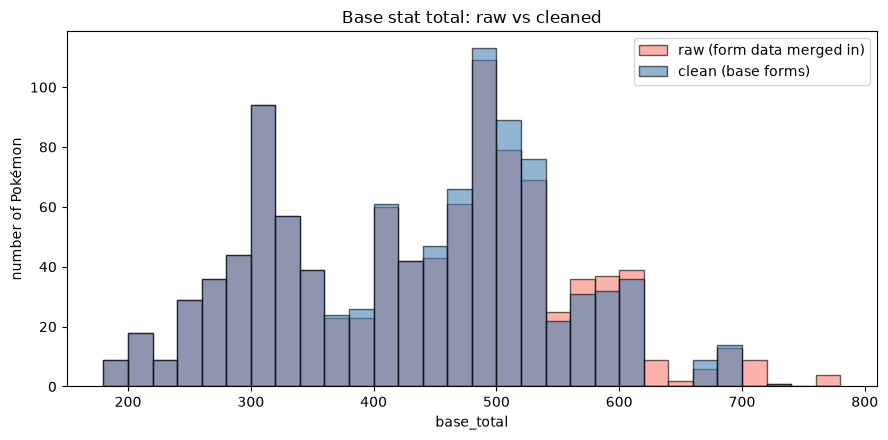

In [4]:
# effect of the reconciliation on the whole distribution
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(180, 800, 20)
ax.hist(pd.to_numeric(raw.base_total), bins=bins, alpha=0.6,
        label="raw (form data merged in)", color="salmon", edgecolor="black")
ax.hist(clean.base_total, bins=bins, alpha=0.6,
        label="clean (base forms)", color="steelblue", edgecolor="black")
ax.set_title("Base stat total: raw vs cleaned")
ax.set_xlabel("base_total")
ax.set_ylabel("number of Pokémon")
ax.legend()
plt.tight_layout()

## 2. Type consistency

* `type2` equal to `type1` (impossible for a real Pokémon) is set to NULL.
* All 18 `against_*` columns are recomputed from the official type chart, so
  they always agree with `type1`/`type2` (dual types multiply).

In [5]:
chart = build_type_chart(load_cached_types())
TYPE_TO_COLUMN = {t: ("against_fight" if t == "fighting" else f"against_{t}")
                  for t in chart}


def against_mismatches(frame, type_cols=True):
    """Count against_* cells that disagree with the declared typing."""
    frame = frame.copy()
    frame["type2"] = frame["type2"].replace("", np.nan)
    bad = 0
    for row in frame.itertuples():
        types = [row.type1] + ([row.type2] if isinstance(row.type2, str) else [])
        for atk, col in TYPE_TO_COLUMN.items():
            expected = 1.0
            for d in types:
                expected *= chart[atk].get(d, 1.0)
            if abs(float(row._asdict()[col]) - expected) > 1e-9:
                bad += 1
    return bad


raw_dupe = (raw.type2.replace("", np.nan).notna() & (raw.type1 == raw.type2)).sum()
clean_dupe = (clean.type2.notna() & (clean.type1 == clean.type2)).sum()
print(f"type2 == type1        : raw {raw_dupe} -> clean {clean_dupe}")
print(f"against_* mismatches  : raw {against_mismatches(raw)} -> clean {against_mismatches(clean)}")

type2 == type1        : raw 7 -> clean 0
against_* mismatches  : raw 95 -> clean 0


## 3. Numeric & text standardisation

* `capture_rate` becomes an integer (Minior's `30 (Meteorite)255 (Core)` → 30).
* `percentage_male` uses the real in-game ratios.
* Ability names match the official ability index; `classfication` is renamed.

In [6]:
print("capture_rate dtype:")
print("  raw  :", raw.capture_rate.dtype, "| exception:",
      raw.loc[~raw.capture_rate.str.fullmatch(r"\d+"), "capture_rate"].tolist())
print("  clean:", clean.capture_rate.dtype, "| non-integers:",
      int((clean.capture_rate % 1 != 0).sum()))

print("\npercentage_male, non-standard values:")
raw_ratio = pd.to_numeric(raw.percentage_male, errors="coerce")
odd_raw = raw_ratio[~raw_ratio.isin(STANDARD_RATIOS) & raw_ratio.notna()]
print("  raw  :", odd_raw.value_counts().to_dict())
odd_clean = clean.percentage_male[~clean.percentage_male.isin(STANDARD_RATIOS)
                                  & clean.percentage_male.notna()]
print("  clean:", odd_clean.value_counts().to_dict() or "none")
print("\npercentage_male distribution after cleaning:")
print(clean.percentage_male.value_counts().sort_index().to_dict())

capture_rate dtype:
  raw  : str | exception: ['30 (Meteorite)255 (Core)']
  clean: int64 | non-integers: 0

percentage_male, non-standard values:
  raw  : {88.1: 111, 24.6: 24, 75.4: 19, 11.2: 2}
  clean: none

percentage_male distribution after cleaning:
{0.0: 37, 12.5: 2, 25.0: 25, 50.0: 630, 75.0: 19, 87.5: 131, 100.0: 26}


In [7]:
# ability spelling check against the official index
idx = json.loads(Path("datasets/raw/ability_index.json").read_text())
official = {r["name"] for r in idx["results"]}
by_norm = {s.replace("-", "").replace(" ", ""): s for s in official}


def misspelled(series):
    bad = {}
    for value in series:
        for token in ast.literal_eval(value):
            candidate = by_norm.get(token.strip().replace("-", "").replace(" ", "").lower())
            if candidate and token.strip().lower() not in {candidate,
                                                           candidate.replace("-", " ").lower()}:
                bad[token] = candidate
    return bad


print("raw ability spellings  :", misspelled(raw.abilities))
print("clean ability spellings:", misspelled(clean.abilities) or "none")
print("column renamed: classfication ->", [c for c in clean.columns if c == "classification"])

raw ability spellings  : {'Compoundeyes': 'compound-eyes', 'Lightningrod': 'lightning-rod'}
clean ability spellings: none
column renamed: classfication -> ['classification']


## 4. Calculated columns

Meaningful derived fields used later for analysis and database loading.

In [8]:
calculated = ["name", "generation_name", "type_pair", "is_dual_type",
              "main_offense", "size_class"]
clean[calculated].head(8)

,name,generation_name,type_pair,is_dual_type,main_offense,size_class
0,Bulbasaur,Generation I,grass / poison,1,special,small
1,Ivysaur,Generation I,grass / poison,1,special,medium
2,Venusaur,Generation I,grass / poison,1,special,large
3,Charmander,Generation I,fire,0,special,small
4,Charmeleon,Generation I,fire,0,special,medium
5,Charizard,Generation I,fire / flying,1,special,medium
6,Squirtle,Generation I,water,0,special,small
7,Wartortle,Generation I,water,0,special,medium


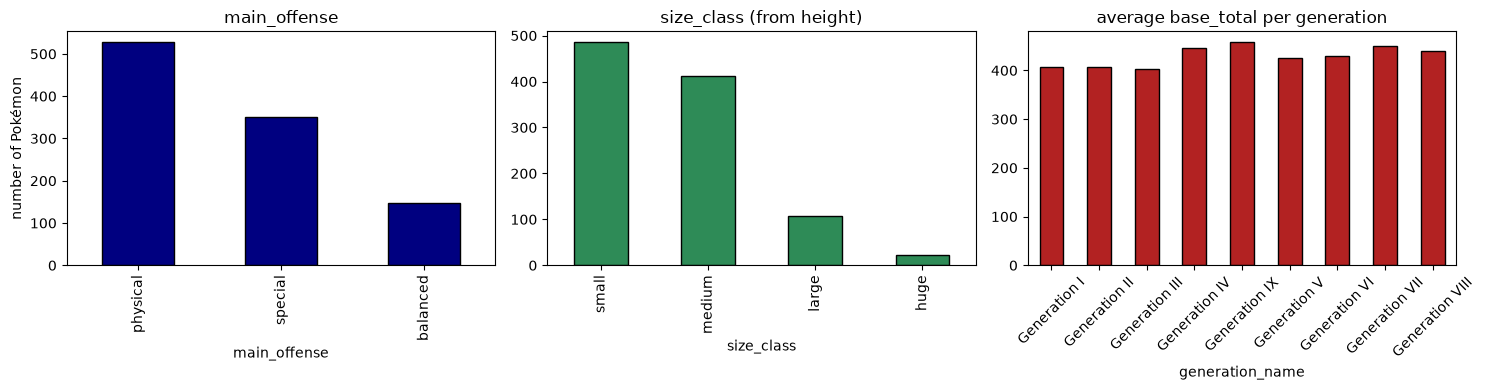

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

clean.main_offense.value_counts().plot(kind="bar", ax=axes[0], color="navy", edgecolor="black")
axes[0].set_title("main_offense")
axes[0].set_ylabel("number of Pokémon")

clean.size_class.value_counts().reindex(["small", "medium", "large", "huge"]).plot(
    kind="bar", ax=axes[1], color="seagreen", edgecolor="black")
axes[1].set_title("size_class (from height)")

clean.groupby("generation_name").base_total.mean().plot(
    kind="bar", ax=axes[2], color="firebrick", edgecolor="black")
axes[2].set_title("average base_total per generation")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()

## 5. Before / after data quality

In [10]:
before = pd.to_numeric(raw.base_total, errors="coerce")
after = clean.base_total
quality = pd.DataFrame({
    "raw": [int(raw.type2.replace("", np.nan).isna().sum()),
            int(pd.to_numeric(raw.height_m, errors="coerce").isna().sum()),
            int(len(raw) - raw.capture_rate.str.fullmatch(r"\d+").sum()),
            int(odd_raw.shape[0])],
    "clean": [int(clean.type2.isna().sum()),
              int(clean.height_m.isna().sum()),
              int(clean.capture_rate.isna().sum()),
              int(odd_clean.shape[0])],
}, index=["blank type2", "blank height_m", "capture_rate not numeric",
          "non-standard percentage_male"])
quality

,raw,clean
blank type2,483,499
blank height_m,20,0
capture_rate not numeric,1,0
non-standard percentage_male,156,0


In [11]:
# the automated checks that the cleaning script enforces
for name, ok, detail in run_checks(clean, chart):
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
    print(f"        {detail}")

[PASS] pokedex_number is unique and complete (1-1025)
        1025 distinct ids, 1-1025
[PASS] name is unique
        1025 names
[PASS] no duplicate type2 == type1
        0 rows
[PASS] all against_* cells match the type chart
        0 mismatching cells of 18450
[PASS] base_total equals the sum of the six stats
        0 rows differ
[PASS] percentage_male uses standard game ratios
        0 non-standard rows
[PASS] capture_rate is a whole number everywhere
        0 missing / non-integer values
[PASS] no unexpected missing values
        blank type2: 499, blank percentage_male: 155, other: none


## 6. Splitting into relational DataFrames

The cleaned data is also written as dimension/fact tables - the input for the
Phase 5 database design and the Phase 6 load.

In [12]:
clean_dir = Path("datasets/clean")
summary = []
for path in sorted(clean_dir.glob("*.csv")):
    frame = pd.read_csv(path)
    summary.append({"table": path.stem, "rows": frame.shape[0], "columns": frame.shape[1]})
pd.DataFrame(summary)

,table,rows,columns
0,abilities,284,2
1,generations,9,5
2,pokemon,1025,20
3,pokemon_abilities,2411,4
4,pokemon_stats,1025,8
5,pokemon_type_defense,18450,3
6,type_matchups,324,3
7,types,18,2


In [13]:
display(pd.read_csv("datasets/clean/pokemon_abilities.csv").head(6))
display(pd.read_csv("datasets/clean/type_matchups.csv").head(6))

,pokedex_number,ability_id,slot,is_hidden
0,1,149,1,0
1,1,24,3,1
2,2,149,1,0
3,2,24,3,1
4,3,149,1,0
5,3,24,3,1


,attacking_type_id,defending_type_id,multiplier
0,1,1,1.0
1,1,2,2.0
2,1,3,1.0
3,1,4,1.0
4,1,5,0.5
5,1,6,0.5


## 7. Summary

* 1025 × 41 → **1025 × 46**: the same rows, five calculated columns added and
  every value now internally consistent.
* 16 Pokémon no longer mix regional/mega data into their base row; `type2`
  duplicates and all `against_*` contradictions are gone.
* `capture_rate` and `percentage_male` are numeric/standard, ability names match
  the official index.
* Outputs: `datasets/pokemon_clean.csv`, eight tables in `datasets/clean/`,
  and the full audit trail in `reports/cleaning_changelog.md`.

**Next:** Phase 4 analysis & insights, then Phase 5 database design (ERD) and
Phase 6 loading the tables into PostgreSQL.